# EDA 02 — FICO HELOC (Explainable ML Challenge)

Nguồn: FICO xAI Challenge — hồ sơ tín dụng của người xin hạn mức vay thế chấp (HELOC), bản *cleaned* (đã loại
các dòng không có hồ sơ tín dụng). Nhãn gốc `RiskPerformance` (`Bad` = từng quá hạn ≥ 90 ngày trong 24 tháng) → `target`.

Lưu ý: dữ liệu dùng **mã âm đặc biệt** thay cho NaN: `-9` = không có bản ghi/không tìm thấy,
`-8` = không có giao dịch hợp lệ, `-7` = điều kiện không xảy ra (ví dụ chưa từng quá hạn).

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.visualization import eda

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
INTERIM = ROOT / "data" / "interim"

## 1. Nạp dữ liệu

In [2]:
NAME = "fico_heloc"
df = pd.read_csv(INTERIM / "fico_heloc.csv")
df.shape

(9871, 24)

## 2. Tổng quan

In [3]:
ov = eda.overview(df)
display(ov.to_frame("value"))
display(df.head())

,value
rows,9871.0
features,23.0
numeric_features,23.0
categorical_features,0.0
duplicate_rows,1.0
cells_missing_pct,0.0
features_with_missing,0.0


,ExternalRiskEstimate,MSinceOldestTradeOpen,MSinceMostRecentTradeOpen,AverageMInFile,NumSatisfactoryTrades,NumTrades60Ever2DerogPubRec,NumTrades90Ever2DerogPubRec,PercentTradesNeverDelq,MSinceMostRecentDelq,MaxDelq2PublicRecLast12M,MaxDelqEver,NumTotalTrades,NumTradesOpeninLast12M,PercentInstallTrades,MSinceMostRecentInqexcl7days,NumInqLast6M,NumInqLast6Mexcl7days,NetFractionRevolvingBurden,NetFractionInstallBurden,NumRevolvingTradesWBalance,NumInstallTradesWBalance,NumBank2NatlTradesWHighUtilization,PercentTradesWBalance,target
0,55,144,4,84,20,3,0,83,2,3,5,23,1,43,0,0,0,33,-8,8,1,1,69,1
1,61,58,15,41,2,4,4,100,-7,0,8,7,0,67,0,0,0,0,-8,0,-8,-8,0,1
2,67,66,5,24,9,0,0,100,-7,7,8,9,4,44,0,4,4,53,66,4,2,1,86,1
3,66,169,1,73,28,1,1,93,76,6,6,30,3,57,0,5,4,72,83,6,4,3,91,1
4,81,333,27,132,12,0,0,100,-7,7,8,12,0,25,0,1,1,51,89,3,1,0,80,1


## 3. Nhãn (target: 1 = xấu / vỡ nợ, 0 = tốt)

{'n': 9871, 'n_bad': 5136, 'n_good': 4735, 'bad_rate_pct': 52.03, 'imbalance_ratio': 0.92}


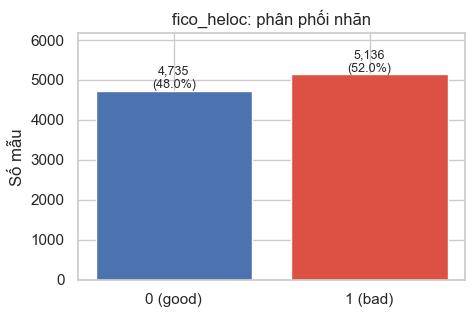

In [4]:
tgt = eda.target_summary(df["target"])
print(tgt)
eda.plot_target(df["target"], NAME)

## 4. Giá trị thiếu

Bảng thứ hai so sánh tỉ lệ nợ xấu khi cột bị thiếu và khi có giá trị: chênh lệch lớn nghĩa là *bản thân việc thiếu* đã mang thông tin về nhãn.

In [5]:
miss = eda.missing_table(df)
display(miss if len(miss) else "Không có giá trị thiếu (NaN).")
mvt = eda.missing_vs_target(df)
display(mvt if len(mvt) else "Không có cột nào đủ lượng thiếu để so sánh bad rate.")

'Không có giá trị thiếu (NaN).'

'Không có cột nào đủ lượng thiếu để so sánh bad rate.'

## 5. Hồ sơ các biến số

`skew`/`kurtosis`: độ lệch và độ nhọn; `outlier_iqr_pct`: % điểm nằm ngoài 1.5×IQR; `zero_pct`: % giá trị 0; `auc`: AUC đơn biến (max(AUC, 1−AUC)) — thước đo nhanh sức phân biệt của từng biến.

In [6]:
prof = eda.numeric_profile(df)
cols_show = ["n_unique", "min", "median", "max", "skew", "kurtosis", "outlier_iqr_pct", "zero_pct", "auc"]
display(prof.sort_values("auc", ascending=False)[cols_show])
print("Số cột số có |skew| > 2:", int((prof["skew"].abs() > 2).sum()), "/", len(prof))

,n_unique,min,median,max,skew,kurtosis,outlier_iqr_pct,zero_pct,auc
feature,,,,,,,,,
ExternalRiskEstimate,61,-9,72.0,94,-0.483,2.992,0.162,0.000,0.769
NetFractionRevolvingBurden,127,-8,28.0,232,0.616,-0.477,0.051,6.159,0.685
PercentTradesWBalance,94,-8,67.0,100,-0.311,-0.402,0.638,0.456,0.662
PercentTradesNeverDelq,71,0,97.0,100,-2.431,7.898,7.041,0.061,0.655
AverageMInFile,236,4,76.0,383,0.920,2.670,2.533,0.000,0.651
MaxDelq2PublicRecLast12M,9,0,6.0,9,-1.777,3.189,3.951,3.404,0.647
MaxDelqEver,7,2,6.0,8,-0.982,0.088,7.487,0.000,0.626
MSinceOldestTradeOpen,525,-8,183.0,803,0.557,0.528,1.682,0.000,0.624
NumBank2NatlTradesWHighUtilization,18,-8,1.0,18,-1.378,5.874,18.509,43.643,0.612


Số cột số có |skew| > 2: 6 / 23


## 6. Phân phối theo nhãn

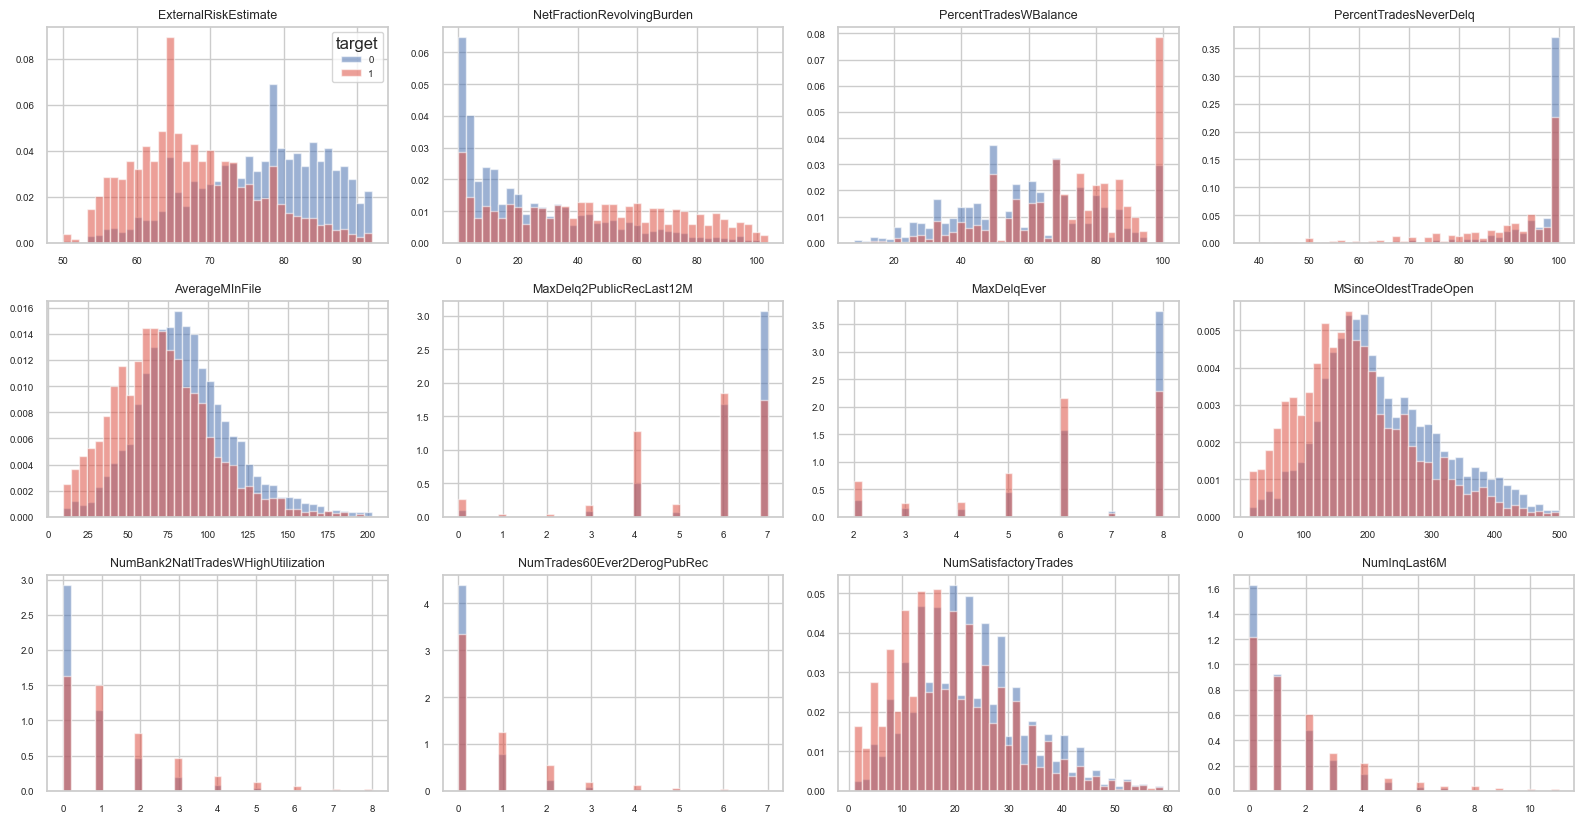

In [7]:
top = prof.sort_values("auc", ascending=False).index[:12].tolist()
eda.plot_numeric_by_target(df.replace({-7: np.nan, -8: np.nan, -9: np.nan}), top, NAME)

## 8. Tương quan

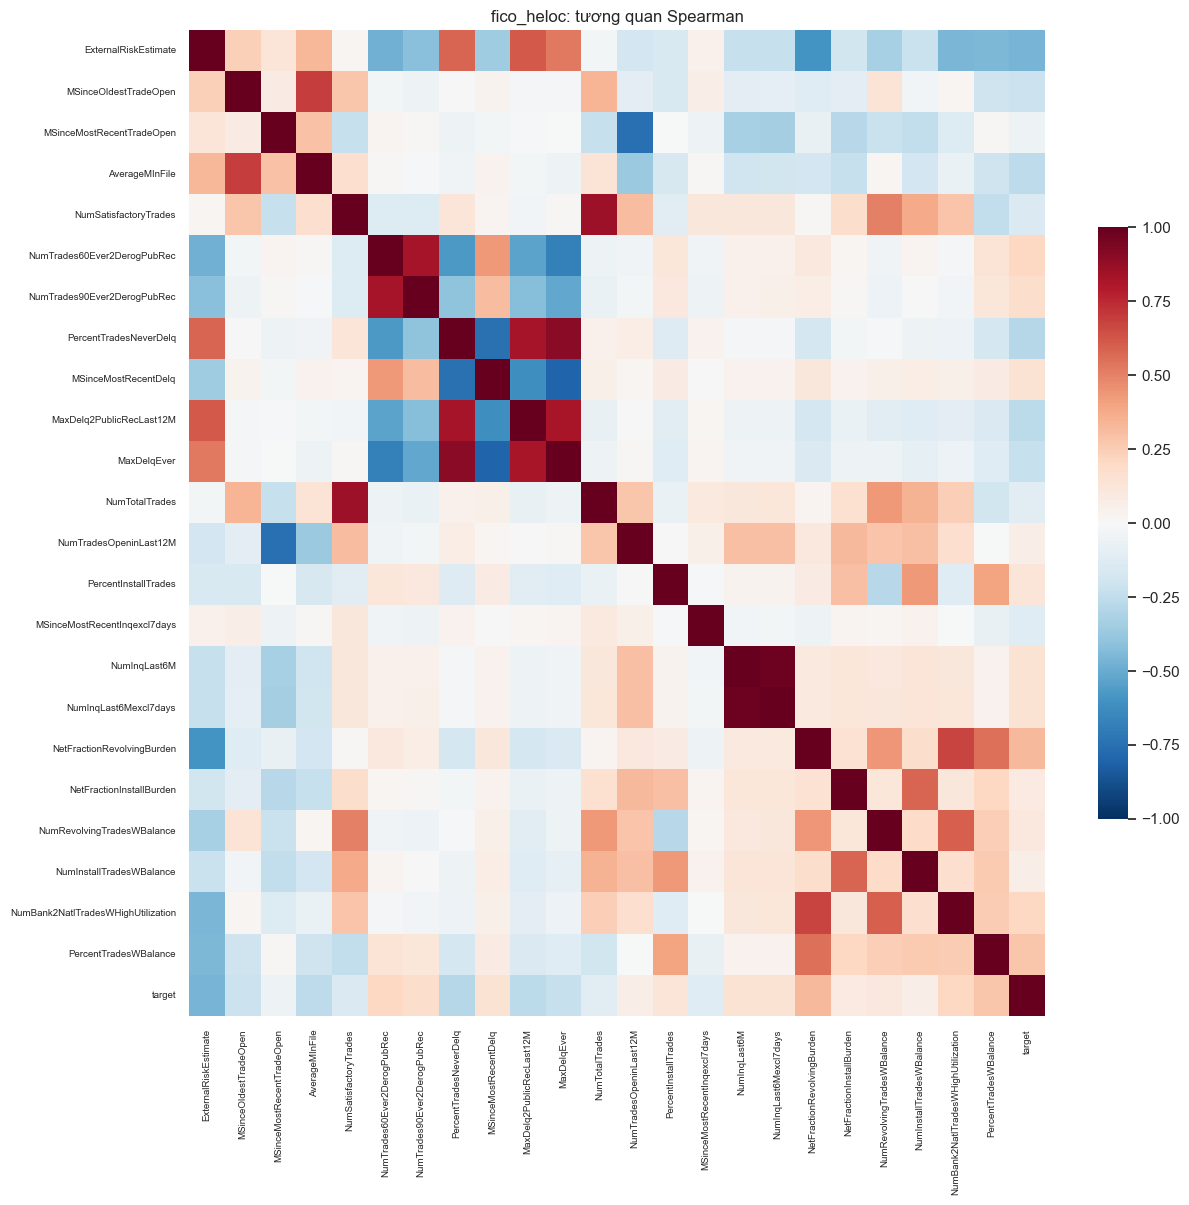

,a,b,spearman
0,NumInqLast6M,NumInqLast6Mexcl7days,0.982358
1,PercentTradesNeverDelq,MaxDelqEver,0.902201


In [8]:
corr = eda.correlation_heatmap(df, NAME)
display(eda.high_corr_pairs(corr, thr=0.9).head(20))

## 9. Kiểm tra riêng cho bộ dữ liệu

### Mã đặc biệt -7 / -8 / -9 (missing “ẩn”)

In [9]:
X = df.drop(columns="target")
special = pd.DataFrame({k: (X == k).mean().mul(100).round(2) for k in (-7, -8, -9)})
display(special[special.sum(axis=1) > 0].sort_values(-7, ascending=False))
for k in (-7, -8):
    m = (X == k).any(axis=1)
    print(f"Dòng có ít nhất một giá trị {k}: {m.mean():.1%} — bad rate {df.loc[m, 'target'].mean():.1%} "
          f"vs {df.loc[~m, 'target'].mean():.1%}")

,-7,-8,-9
MSinceMostRecentDelq,47.25,1.78,0.0
MSinceMostRecentInqexcl7days,18.79,4.82,0.0
ExternalRiskEstimate,0.00,0.00,0.1
MSinceOldestTradeOpen,0.00,2.42,0.0
NetFractionRevolvingBurden,0.00,1.88,0.0
NetFractionInstallBurden,0.00,34.64,0.0
NumRevolvingTradesWBalance,0.00,1.58,0.0
NumInstallTradesWBalance,0.00,8.72,0.0
NumBank2NatlTradesWHighUtilization,0.00,5.91,0.0
PercentTradesWBalance,0.00,0.18,0.0


Dòng có ít nhất một giá trị -7: 57.6% — bad rate 45.2% vs 61.3%
Dòng có ít nhất một giá trị -8: 42.8% — bad rate 48.5% vs 54.7%


In [10]:
# Biến mạnh nhất: ExternalRiskEstimate (điểm rủi ro tổng hợp)
bins = pd.cut(df["ExternalRiskEstimate"].where(df["ExternalRiskEstimate"] > 0), [0, 60, 65, 70, 75, 80, 85, 100])
display(df.groupby(bins, observed=True)["target"].agg(["size", "mean"]))

,size,mean
ExternalRiskEstimate,,
"(0, 60]",1313,0.830160
"(60, 65]",1546,0.766494
"(65, 70]",1690,0.655030
"(70, 75]",1618,0.494438
"(75, 80]",1383,0.350687
"(80, 85]",1251,0.235811
"(85, 100]",1060,0.156604


## 10. Nhận xét

- **Nhãn:** bad rate ≈ **52%** — gần như **cân bằng**, rất khác các bộ dữ liệu tín dụng thực tế (thường 5–20%). Đây là mẫu đã được FICO chọn lọc/cân bằng cho cuộc thi, nên xác suất dự đoán **không phản ánh tỉ lệ vỡ nợ thật** và cần hiệu chỉnh (calibration / prior correction) nếu dùng ngoài thực tế.
- **Không có NaN nhưng có missing ẩn:** mã `-7` xuất hiện ở ~58% số dòng, `-8` ở ~43%. Nếu coi chúng là số thực, các thống kê min/skew bị sai lệch → cần mã hoá lại (NaN + cờ chỉ báo).
- **Phân phối:** nhiều biến là tỉ lệ phần trăm bị chặn [0,100] hoặc biến đếm; độ lệch chủ yếu ở các biến đếm số lần hỏi tín dụng (`NumInqLast6M`, skew > 6) và số giao dịch xấu. Nhìn chung ít lệch hơn GMSC/Taiwan.
- **Tín hiệu:** `ExternalRiskEstimate` (AUC đơn biến ≈ 0,77) chiếm ưu thế; bad rate giảm đơn điệu theo điểm này. Nhiều cặp biến gần như trùng lặp (vd. `NumInqLast6M` ↔ `NumInqLast6Mexcl7days`).
- Chỉ 1 dòng trùng lặp.

In [11]:
EXTRA = {}
eda.save_summary(NAME, {
    "name": NAME,
    "overview": ov.to_dict(),
    "target": tgt,
    "missing_top": miss["missing_pct"].head(10).to_dict() if len(miss) else {},
    "n_numeric_abs_skew_gt2": int((prof["skew"].abs() > 2).sum()),
    "n_numeric": int(len(prof)),
    "max_abs_skew": float(prof["skew"].abs().max()),
    "top_auc": prof["auc"].sort_values(ascending=False).head(5).to_dict(),
    **EXTRA,
})